**Human Movement Intelligence | Multimodal Movement Learning | Presented by: Reza Saadatyar (2026)**

**05 | Frozen Person-Independent Multimodal Evaluation**

![Frozen Person-Independent Multimodal Evaluation workflow](../../images/05_frozen_person_independent_test.svg)

**Research objective:** Evaluate the Development-frozen sEMG-only Random Forest (`B1_rf`) against the matched early-fusion Random Forest (`F1_rf`) on five reserved NinaPro DB2 Exercise E1 participants, without Test-based model selection.

**Study design:** Refit both fixed 120-tree estimators on the same 35 Development participants using the original aligned 48-column sEMG and 96-column acceleration features. Score 5,000 previously held-out windows from five complete Test participants, with fixed classes 0–17 and equal participant weighting.

**Recorded independent Test result:** Participant-mean macro F1 was **0.2512** for `B1_rf` and **0.3126** for `F1_rf` (paired difference **+0.0614**); the difference was positive for all five reserved participants. These observations are offline, within-dataset evidence. They do not establish clinical, real-time or cross-device performance. The SVG above depicts the frozen experimental workflow, not a numerical result.

**00. Colab Repository Setup**

In [1]:
# ======================== 00. Colab Repository Setup =========================

# -------------------------- 1. Repository Checkout ---------------------------
from pathlib import Path
import subprocess

repo_url = "https://github.com/RezaSaadatyar/human-movement-intelligence.git"
repo_path = Path("/content") / repo_url.rsplit("/", 1)[-1].removesuffix(".git")
if not repo_path.exists():
    subprocess.run(["git", "clone", "-q", repo_url, str(repo_path)], check=True)

# ---------------------------- 2. Open Repository -----------------------------
%cd {repo_path}


/content/human-movement-intelligence


**01. Imports and Research Environment**

In [2]:
# =================== 01. Imports and Research Environment ====================

# ------------------------ 1. Study Environment Setup -------------------------
from python_modules.core.colab_setup import setup_colab
root = setup_colab("multimodal_movement_learning")

# ---------------------------- 2. Standard Library ----------------------------
import shutil
import time

# ----------------- 3. Scientific Computing and Data Analysis -----------------
import numpy as np
import pandas as pd

# ------------------- 4. Visualisation and Notebook Display -------------------
import matplotlib.pyplot as plt
from IPython.display import display
from core.plot_style import plot_style, save_figure
from core.output_download import download_outputs_from_colab

plot_style(
    font_family="DejaVu Sans", title_size=12.5, title_weight="normal",
    label_size=11.5, label_weight="normal", tick_size=11,
    legend_size=10, figure_dpi=100, figure_size=(9, 4),
)
# -------------------- 5. Deep Learning and Compute Device --------------------
from sklearn.metrics import confusion_matrix, precision_recall_fscore_support
from core.computer_device import computer_device
device = computer_device(min_vram_gb=None)

# ------------------------ 6. Study Research Utilities ------------------------
from ninapro_dataset import check_artifact_alignment, ensure_numerical_cache
from ninapro_evaluation import (
    build_classical, classical_features, aligned_probabilities,
    participant_metrics, predictions_from_probabilities,
    paired_subject_bootstrap,
)
from ninapro_models import UNIMODAL_MODELS, FUSION_MODELS
from ninapro_training import fit_neural, predict_neural, benchmark_cpu

# ---------------------- 7. Source and Output Locations -----------------------
study_dir = root / "multimodal_movement_learning"
output_dir = study_dir / "output"
processed_dir = root / "data" / "processed" / "ninapro_db2"
raw_dir = root / "data" / "raw" / "ninapro_db2"
output_dir.mkdir(parents=True, exist_ok=True)
processed_dir.mkdir(parents=True, exist_ok=True)
print("Research output directory:", output_dir)


Local changes kept; continuing with the current checkout. Conflicting Git update deferred.
Compute device and system information
OS: Linux 6.6.159+
CPU: x86_64
Installed RAM: 12.7 GiB
NVIDIA GPU: Tesla T4
Total VRAM: 15.00 GiB
PyTorch version: 2.14.1+cu130
CUDA device: Tesla T4
CUDA runtime: 13.0
cuDNN version: 92800
PyTorch total VRAM: 14.56 GiB
Selected compute device: cuda
Research output directory: /content/human-movement-intelligence/multimodal_movement_learning/output


**02. Read Frozen Development Selection Before Test Evaluation**

The frozen `04_model_selection.csv` selects **`B1_rf` (sEMG-only)** and **`F1_rf` (early fusion)** using grouped Development evidence, before Test scoring. Both recipes retain the original fixed source-class order (0–17). The loaded neural epoch histories belong to the study's general final-fit interface; no neural architecture or epoch count was selected for this particular Test run.

In [3]:
# ======= 02. Read Frozen Development Selection Before Test Evaluation ========

NOTEBOOK_NUMBER = 5
SEED = 42
selection = pd.read_csv(output_dir / "04_model_selection.csv").fillna("")
if set(selection.selection_role) != {"unimodal_comparator", "fusion_comparator"}:
    raise ValueError("Exactly one selected unimodal and one selected fusion recipe are required.")
best_unimodal = str(selection.set_index("selection_role").loc["unimodal_comparator", "model_id"])
best_fusion = str(selection.set_index("selection_role").loc["fusion_comparator", "model_id"])
late_emg = str(selection.set_index("selection_role").loc["fusion_comparator", "component_emg"])
late_acc = str(selection.set_index("selection_role").loc["fusion_comparator", "component_acc"])
classes = np.sort(pd.read_csv(output_dir / "01_label_dictionary.csv").label.to_numpy(int))
train_evidence = pd.concat([
    pd.read_csv(output_dir / "03_dev_neural_metrics.csv"),
    pd.read_csv(output_dir / "04_dev_deep_fusion_metrics.csv"),
], ignore_index=True)
print("Frozen unimodal comparator:", best_unimodal)
print("Frozen fusion comparator:", best_fusion)
print("Source classes:", classes.tolist())


Frozen unimodal comparator: B1_rf
Frozen fusion comparator: F1_rf
Source classes: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17]


**03. Validate Independent Subject Roles and Input Contracts**

The saved split assigns **35 participants (35,000 windows)** to Development and **five participants (5,000 windows)** to the independent Test group: S05, S08, S19, S33 and S40. The two final Random Forests need only the source-aligned **48-column sEMG** and **96-column acceleration** feature arrays, retaining the original 40,000 window-row order and finite values. These two `.npy` feature matrices are now tracked at `data/processed/ninapro_db2/`; the optional mounted Google Drive fallback is used only if they are unavailable locally. Raw temporal recordings are not needed for the two chosen classical estimators. The completed execution successfully reused the paired features without regenerating the original recordings.

In [4]:
# ======== 03. Validate Independent Subject Roles and Input Contracts =========

# ------------------------ 1. Validate Roles and Split ------------------------
index = pd.read_csv(output_dir / "02_window_index.csv")
roles = pd.read_csv(output_dir / "02_participant_split_assignments.csv")
index["role"] = index.subject_id.map(dict(zip(roles.subject_id, roles.role)))
if index.role.isna().any():
    raise ValueError("A source participant has no frozen Development/Test role.")
development = index.loc[index.role == "Development"].copy()
test = index.loc[index.role == "Test"].copy()
if not len(development) or not len(test):
    raise ValueError("Both reserved Test and Development windows are required.")
if set(development.subject_id) & set(test.subject_id):
    raise ValueError("Participant overlap invalidates the independent Test comparison.")

# ------------------------ 2. Validate Input Contracts ------------------------
# The Development-frozen choices are both classical Random Forest models.
# Avoid reconstructing the 40 subject recordings when only cached statistical
# features are needed; retain the original temporal path for neural choices.
classical_candidates = {
    "B0_prior", "B1_logreg", "B1_rf", "B2_logreg", "B2_rf",
    "F1_logreg", "F1_rf",
}
if {best_unimodal, best_fusion} <= classical_candidates:
    emg_path = processed_dir / "02_emg_features.npy"
    acc_path = processed_dir / "02_acc_features.npy"
    missing = [p.name for p in (emg_path, acc_path) if not p.is_file()]
    if missing:
        # Optional persistent cache: use only the two required matrices from
        # an already mounted Google Drive, without retrieving source recordings.
        drive_cache = Path("/content/drive/MyDrive/HMI/ninapro_db2")
        for path in (emg_path, acc_path):
            backup = drive_cache / path.name
            if not path.is_file() and backup.is_file():
                shutil.copy2(backup, path)
        missing = [p.name for p in (emg_path, acc_path) if not p.is_file()]
    if missing:
        raise FileNotFoundError(
            "Notebook 05's selected classical comparators need only two "
            "Notebook 02 feature matrices. Restore these files to "
            f"{processed_dir} before continuing: {missing}. "
            "No new feature extraction or raw-source download is required."
        )
    emg_features = np.load(emg_path, mmap_mode="r", allow_pickle=False)
    acc_features = np.load(acc_path, mmap_mode="r", allow_pickle=False)
    check_artifact_alignment(index, (emg_features, acc_features))
    if (
        emg_features.shape != (len(index), 48)
        or acc_features.shape != (len(index), 96)
        or not np.isfinite(emg_features).all()
        or not np.isfinite(acc_features).all()
    ):
        raise ValueError("Cached classical features violate Notebook 02's contract.")
    print("Reused paired statistical feature matrices (no raw-signal recovery).")
else:
    # A future neural fusion selection still needs the original temporal arrays.
    emg_features, acc_features = ensure_numerical_cache(
        root, index, allow_source_download=True, verbose=True,
    )
print("Development people:", development.subject_id.nunique())
print("Reserved Test people:", test.subject_id.nunique())
print("Test paired windows:", len(test))


Reused paired statistical feature matrices (no raw-signal recovery).
Development people: 35
Reserved Test people: 5
Test paired windows: 5000


**04. Define Final Fit Epochs from Development Only**

This section provides the fixed-epoch rule for the notebook's **conditional neural-model pathway**: the median of Training-only best epochs observed during Development would be used for a neural final refit. **No fixed-epoch neural refit was required or performed in this execution**, because both frozen comparators are Random Forest classifiers. Test labels played no role in choosing architectures, epochs or stopping decisions.

In [5]:
# ============= 04. Define Final Fit Epochs from Development Only =============

def final_epochs(name):
    observed = train_evidence.loc[
        (train_evidence.model_id == name) &
        train_evidence.best_epochs.notna(), "best_epochs",
    ]
    if observed.empty:
        raise ValueError(f"Missing Development epoch-selection evidence for {name}")
    return max(1, int(np.rint(np.median(observed))))

for name in [best_unimodal, best_fusion, late_emg, late_acc]:
    if name in (*UNIMODAL_MODELS, *FUSION_MODELS):
        print(name, "frozen refit epochs:", final_epochs(name))


**05. Refit Selected Unimodal and Fusion Pipelines**

Both selected **120-tree Random Forests** were refitted on all 35 permitted Development participants with the frozen model settings (including `min_samples_leaf=2`, `max_features="sqrt"`, balanced subsampling and seed 42). `B1_rf` uses the 48 sEMG features; `F1_rf` combines these with the 96 acceleration features (144 total). Random Forests **do not use a fitted StandardScaler** in this implementation. No Test participants were used in estimator fitting, and no trained models or probabilities from Notebook 04 were substituted for these final Development-only refits.

In [6]:
# ============= 05. Refit Selected Unimodal and Fusion Pipelines ==============

# -------------------------- 1. Fit Component Models --------------------------
classical_names = {"B0_prior", "B1_logreg", "B1_rf", "B2_logreg", "B2_rf",
                   "F1_logreg", "F1_rf"}
trained = {}
fit_details = {}

# ------------------------- 2. Fit Component Function -------------------------
def _fit_component(name):
    if name in trained:
        return
    start = time.perf_counter()
    if name in classical_names:
        model = build_classical(name, seed=SEED)
        features = classical_features(name,
            emg_features[development.window_row], acc_features[development.window_row])
        model.fit(features, development.label.to_numpy(int))
        import pickle
        details = {"fit_seconds": time.perf_counter() - start,
                   "model_size_bytes": len(pickle.dumps(model)),
                   "parameter_count": np.nan, "final_fit_epochs": np.nan}
        trained[name] = (model, None)
    elif name in (*UNIMODAL_MODELS, *FUSION_MODELS):
        model, stats, history, info = fit_neural(
            name, development, processed_dir, classes, device=device,
            seed=SEED, fixed_epochs=final_epochs(name),
        )
        details = {"fit_seconds": info["fit_seconds"],
                   "model_size_bytes": sum(p.nelement()*p.element_size()
                                           for p in model.parameters()),
                   "parameter_count": info["parameter_count"],
                   "final_fit_epochs": info["best_epochs"]}
        trained[name] = (model, stats)
    else:
        raise ValueError(f"Unsupported frozen component: {name}")
    fit_details[name] = details

# ------------------------ 3. Fit Selected Components -------------------------
if best_fusion.startswith("F2_"):
    suffix = best_fusion.split("_", 1)[1]
    late_components = (f"B1_{suffix}", f"B2_{suffix}")
elif best_fusion == "F4_deep_late":
    late_components = (late_emg, late_acc)
else:
    late_components = ()
for model_name in dict.fromkeys([best_unimodal, *late_components,
                                  *([] if late_components else [best_fusion])]):
    _fit_component(model_name)
print("Final fitted component models:", list(trained))


Final fitted component models: ['B1_rf', 'F1_rf']


**06. Generate Held-Out Test Probabilities and Measure Costs**

Both frozen models generated aligned, normalised 18-class probabilities for exactly the same 5,000 Test windows. CPU inference time was measured on a **64-window sample** with two warm-up calls and five repeated calls; this is a small-run timing measurement, not a system-level benchmark. The recorded times were **0.579 ms/window** for `B1_rf` and **0.551 ms/window** for `F1_rf`. Training and source recovery are excluded from these inference timings. The slight measured difference should not be generalised into a stable speed ranking without more extensive benchmarking.

In [7]:
# ======== 06. Generate Held-Out Test Probabilities and Measure Costs =========

# -------------------- 1. Predict Component Probabilities ---------------------
def _predict_component(name):
    model, stats = trained[name]
    if stats is None:
        p = aligned_probabilities(model, classical_features(name,
            emg_features[test.window_row], acc_features[test.window_row]), classes)
        sample = classical_features(name,
            emg_features[test.window_row.iloc[:min(64, len(test))]],
            acc_features[test.window_row.iloc[:min(64, len(test))]])
        for _ in range(2): model.predict_proba(sample)
        start = time.perf_counter()
        for _ in range(5): model.predict_proba(sample)
        latency = (time.perf_counter() - start) * 1000 / (5 * len(sample))
    else:
        p = predict_neural(name, model, test, processed_dir, classes,
                           stats, device=device)
        latency = benchmark_cpu(name, model, test, processed_dir, classes, stats)
    return p, float(latency)

probability_cache = {}
latency_cache = {}
for component in trained:
    probability_cache[component], latency_cache[component] = _predict_component(component)

# ----------------------- 2. Select Final Probabilities -----------------------
def _selected_probability(name):
    if name == best_fusion and late_components:
        return 0.5 * (probability_cache[late_components[0]] +
                      probability_cache[late_components[1]])
    return probability_cache[name]

comparison = {
    "unimodal_comparator": best_unimodal,
    "fusion_comparator": best_fusion,
}
comparison_probabilities = {role: _selected_probability(name)
                            for role, name in comparison.items()}
for role, proba in comparison_probabilities.items():
    if proba.shape != (len(test), len(classes)) or not np.allclose(proba.sum(axis=1), 1, atol=1e-4):
        raise ValueError(f"Invalid final fixed-class probabilities: {role}")
print("Matched Test predictions constructed for both frozen comparators.")


Matched Test predictions constructed for both frozen comparators.


**07. Score Fixed-Class Outcomes at the Participant Level**

The primary outcome is macro F1 computed over the **fixed 18 source classes independently for each Test participant**, then averaged equally over the five people. The recorded means were **0.2512** for `B1_rf` and **0.3126** for `F1_rf`. Corresponding mean fixed-class balanced accuracy was **0.2879** and **0.3510**, respectively. Overall window accuracy (0.5108 and 0.5738 across the five equally sized Test participants) is secondary and sensitive to the prevalent Rest class. The saved predictions retain original window keys and all 18 class-probability columns.

In [8]:
# ========== 07. Score Fixed-Class Outcomes at the Participant Level ==========

# ------------------------- 1. Score and Save Results -------------------------
metric_frames, prediction_frames, cost_rows = [], [], []
for role, model_name in comparison.items():
    proba = comparison_probabilities[role]
    score = participant_metrics(test.reset_index(drop=True), proba,
                                classes, model_id=model_name, seed=SEED)
    score["comparison_role"] = role
    metric_frames.append(score)
    frame = test[["window_key", "subject_id", "segment_id", "repetition_id",
                  "start_s", "end_s", "label"]].copy().reset_index(drop=True)
    frame["model_id"] = model_name
    frame["comparison_role"] = role
    frame["predicted_label"] = predictions_from_probabilities(proba, classes)
    for j, source_class in enumerate(classes):
        frame[f"p_class_{int(source_class)}"] = proba[:, j]
    prediction_frames.append(frame)
    components = late_components if (role == "fusion_comparator" and late_components) else (model_name,)
    cost_rows.append({
        "comparison_role": role, "model_id": model_name,
        "fit_seconds": sum(fit_details[c]["fit_seconds"] for c in components),
        "model_size_bytes": sum(fit_details[c]["model_size_bytes"] for c in components),
        "parameter_count": (
            float(sum(fit_details[c]["parameter_count"] for c in components))
            if all(np.isfinite(fit_details[c]["parameter_count"])
                   for c in components)
            else np.nan
        ),
        "cpu_ms_per_window": sum(latency_cache[c] for c in components),
    })

# ------------------------------ 2. Save Results ------------------------------
test_metrics = pd.concat(metric_frames, ignore_index=True)
test_predictions = pd.concat(prediction_frames, ignore_index=True)
test_metrics.to_csv(output_dir / "05_test_metrics.csv", index=False)
test_predictions.to_csv(output_dir / "05_test_predictions.csv", index=False)
costs = pd.DataFrame(cost_rows)
costs.to_csv(output_dir / "05_model_costs.csv", index=False)
display(test_metrics.groupby("comparison_role", as_index=False).agg(
    participant_mean_macro_f1=("macro_f1", "mean"),
    participant_mean_balanced_accuracy=("fixed_class_balanced_accuracy", "mean"),
    independent_people=("subject_id", "nunique")))


,comparison_role,participant_mean_macro_f1,participant_mean_balanced_accuracy,independent_people
0,fusion_comparator,0.312600,0.350991,5
1,unimodal_comparator,0.251178,0.287890,5


**08. Quantify Paired Participant Differences and Uncertainty**

For each Test participant, the prespecified difference is `F1_rf` minus `B1_rf` macro F1 on the **same windows**. All **five of five** paired differences were positive, ranging from **+0.0083 (S19)** to **+0.0874 (S08)**. Their equal-participant mean was **+0.0614** macro-F1 units. A **2,000-draw participant-level paired bootstrap** gave descriptive percentile limits **0.0333–0.0804**. Only five independently held-out people contribute to this interval; it is conditional on the fitted models and does not demonstrate population-wide superiority or justify further Test-driven model selection.

In [9]:
# ======== 08. Quantify Paired Participant Differences and Uncertainty ========

wide = test_metrics.pivot(index="subject_id", columns="comparison_role",
                          values="macro_f1")
wide["fusion_minus_unimodal"] = (wide["fusion_comparator"] -
                                 wide["unimodal_comparator"])
uncertainty = paired_subject_bootstrap(wide.fusion_minus_unimodal.to_numpy(), seed=SEED)
summary = pd.DataFrame([{
    "fusion_model": best_fusion, "unimodal_model": best_unimodal,
    "fusion_mean_subject_macro_f1": float(wide.fusion_comparator.mean()),
    "unimodal_mean_subject_macro_f1": float(wide.unimodal_comparator.mean()),
    **uncertainty,
}])
summary.to_csv(output_dir / "05_test_summary.csv", index=False)
wide.reset_index().to_csv(output_dir / "05_subject_differences.csv", index=False)
display(summary.T.rename(columns={0: "observed estimate"}))


,observed estimate
fusion_model,F1_rf
unimodal_model,B1_rf
fusion_mean_subject_macro_f1,0.3126
unimodal_mean_subject_macro_f1,0.251178
mean_difference,0.061423
bootstrap_2_5pct,0.033337
bootstrap_97_5pct,0.080434
independent_test_people,5
bootstrap_draws,2000


**09. Interpret Per-Class Errors and Runtime Trade-Offs**

The class table reports **pooled-window** precision, recall, F1, true support and predicted-window counts for both models. These metrics have a different aggregation rule from the primary **participant-mean** macro F1 and must not be substituted for it. Rest (class 0) accounts for **2,691 of 5,000 Test windows (53.8%)**. The corresponding Development set contains **16,329 of 35,000 Rest windows (46.7%)**, so class prevalence differs across the fixed participant split and pooled window accuracy is particularly sensitive to this composition. For `F1_rf`, pooled Rest recall was **0.8194**, but class-7 and class-8 F1 were only **0.0290** and **0.0694**, respectively. Thus the observed overall fusion gain does not imply reliable recognition across every movement class.

The paired difference chart displays all five independent people. The count confusion matrix is dominated visually by Rest, whereas the **true-class-row-normalised confusion matrix** highlights movement-specific recall and errors. The cost-versus-performance scatter compares two fitted models only; both axes use narrow ranges, and minor latency differences from this small timing sample should not be over-interpreted.

,comparison_role,model_id,label,support,predicted_windows,precision,recall,f1
0,unimodal_comparator,B1_rf,0,2691,2387,0.850021,0.753995,0.799134
1,unimodal_comparator,B1_rf,1,212,179,0.145251,0.122642,0.132992
2,unimodal_comparator,B1_rf,2,159,234,0.042735,0.062893,0.050891
3,unimodal_comparator,B1_rf,3,144,157,0.203822,0.222222,0.212625
4,unimodal_comparator,B1_rf,4,129,122,0.065574,0.062016,0.063745
5,unimodal_comparator,B1_rf,5,103,78,0.166667,0.126214,0.143646
6,unimodal_comparator,B1_rf,6,99,104,0.432692,0.454545,0.443350
7,unimodal_comparator,B1_rf,7,175,108,0.037037,0.022857,0.028269
8,unimodal_comparator,B1_rf,8,131,56,0.017857,0.007634,0.010695
9,unimodal_comparator,B1_rf,9,149,333,0.246246,0.550336,0.340249


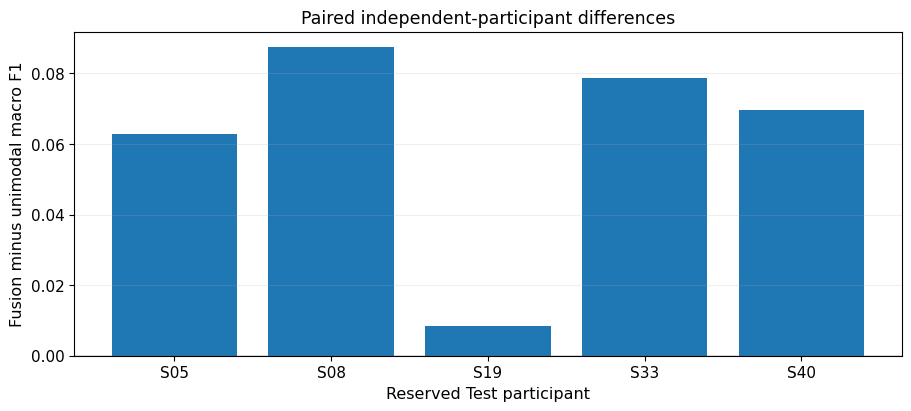

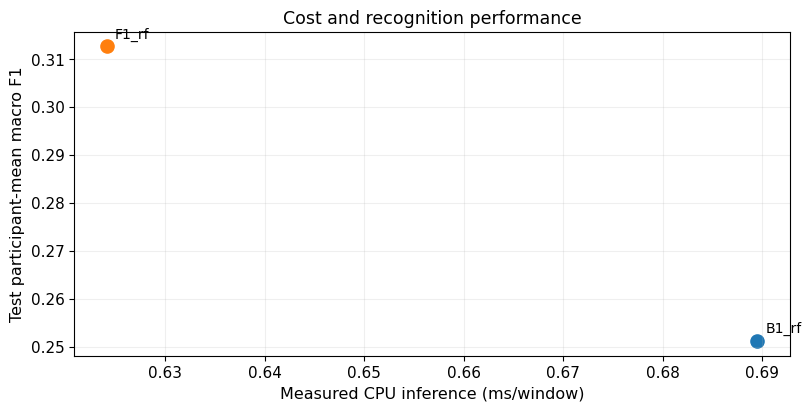

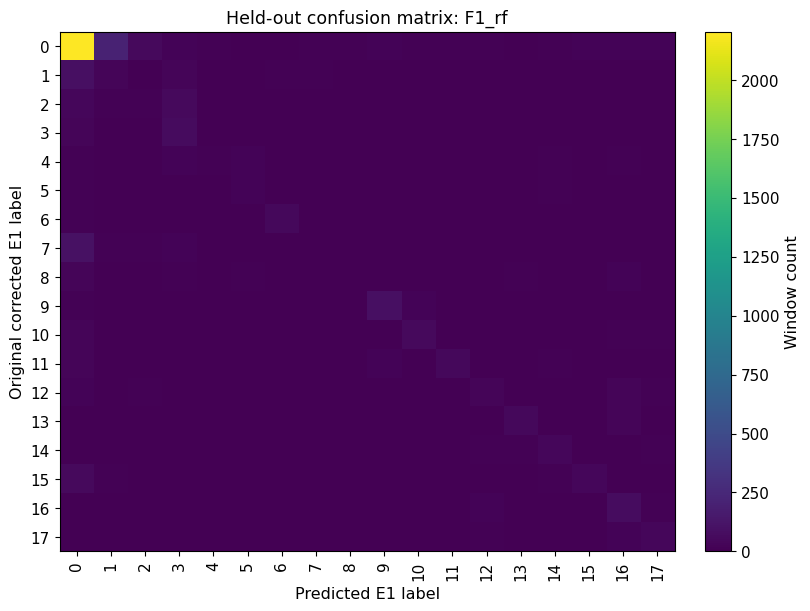

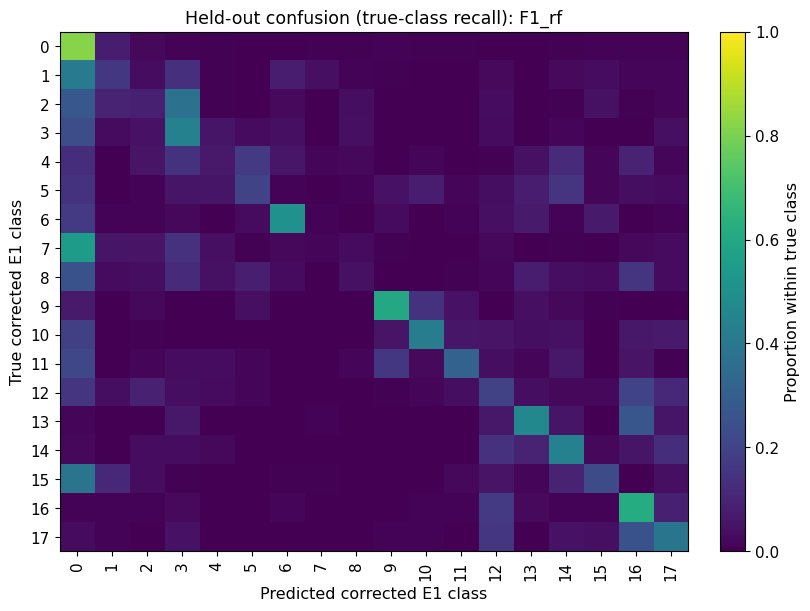

In [10]:
# =========== 09. Generate Per-Class Support and Confusion Matrices ===========

# --------------------- 1. Per-Class Support and Metrics ----------------------
per_class_rows = []
for role, model_name in comparison.items():
    pred = predictions_from_probabilities(
        comparison_probabilities[role], classes,
    )
    precision, recall, class_f1, support = precision_recall_fscore_support(
        test.label.to_numpy(int), pred, labels=classes, zero_division=0,
    )
    predicted_windows = np.bincount(
        np.searchsorted(classes, pred), minlength=len(classes),
    )
    for i, label in enumerate(classes):
        per_class_rows.append({
            "comparison_role": role,
            "model_id": model_name,
            "label": int(label),
            "support": int(support[i]),
            "predicted_windows": int(predicted_windows[i]),
            "precision": float(precision[i]),
            "recall": float(recall[i]),
            "f1": float(class_f1[i]),
        })
per_class = pd.DataFrame(per_class_rows)
per_class.to_csv(output_dir / "05_per_class_support.csv", index=False)
display(per_class)

# --------------------- 2. Paired Participant Differences ---------------------
fig, ax = plt.subplots(figsize=(9, 4), layout="constrained")
ax.bar(wide.index, wide.fusion_minus_unimodal)
ax.axhline(0, color="0.4", lw=1)
ax.set(xlabel="Reserved Test participant", ylabel="Fusion minus unimodal macro F1",
       title="Paired independent-participant differences")
ax.grid(axis="y", alpha=.2)
save_figure(fig, output_dir / "05_subject_differences.png")
plt.show()

# -------------------- 3. Cost and Recognition Performance --------------------
fig, ax = plt.subplots(figsize=(8, 4), layout="constrained")
for row in costs.itertuples(index=False):
    score = test_metrics.loc[test_metrics.comparison_role == row.comparison_role, "macro_f1"].mean()
    ax.scatter(row.cpu_ms_per_window, score, s=90)
    ax.annotate(row.model_id, (row.cpu_ms_per_window, score), xytext=(6, 6),
                textcoords="offset points")
ax.set(xlabel="Measured CPU inference (ms/window)", ylabel="Test participant-mean macro F1",
       title="Cost and recognition performance")
ax.grid(alpha=.2)
save_figure(fig, output_dir / "05_cost_accuracy.png")
plt.show()

# -------------------- 4. Confusion Matrix and Normalised ---------------------
pred = predictions_from_probabilities(comparison_probabilities["fusion_comparator"], classes)
cm = confusion_matrix(test.label.to_numpy(int), pred, labels=classes)
fig, ax = plt.subplots(figsize=(8, 6), layout="constrained")
im = ax.imshow(cm, aspect="auto")
ax.set(xlabel="Predicted E1 label", ylabel="Original corrected E1 label",
       title=f"Held-out confusion matrix: {best_fusion}")
ax.set_xticks(np.arange(len(classes)), labels=classes, rotation=90)
ax.set_yticks(np.arange(len(classes)), labels=classes)
fig.colorbar(im, ax=ax, label="Window count")
save_figure(fig, output_dir / "05_confusion_matrix.png")
plt.show()

# -------------------- 5. Row-Normalised Confusion Matrix ---------------------
# Row-normalised confusion gives each source class a comparable visual scale.
# Unsupported true classes (if any) have zero-valued rows by convention.
class_support = cm.sum(axis=1, keepdims=True)
cm_normalised = np.divide(
    cm, class_support, out=np.zeros_like(cm, dtype=float),
    where=class_support > 0,
)
fig, ax = plt.subplots(figsize=(8, 6), layout="constrained")
im = ax.imshow(cm_normalised, aspect="auto", vmin=0, vmax=1)
ax.set(
    xlabel="Predicted corrected E1 class",
    ylabel="True corrected E1 class",
    title=f"Held-out confusion (true-class recall): {best_fusion}",
)
ax.set_xticks(np.arange(len(classes)), labels=classes, rotation=90)
ax.set_yticks(np.arange(len(classes)), labels=classes)
fig.colorbar(im, ax=ax, label="Proportion within true class")
save_figure(fig, output_dir / "05_confusion_matrix_normalised.png")
plt.show()



**10. Current Outputs and Scientific Interpretation**

**Recorded Test finding:** On the five previously reserved NinaPro DB2 E1 people, frozen early fusion `F1_rf` achieved **0.3126** participant-mean macro F1 versus **0.2512** for the frozen sEMG-only `B1_rf`, a paired mean advantage of **+0.0614** units (descriptive 2,000-resample participant-bootstrap percentile interval **0.0333–0.0804**). Each of the five people showed a positive observed difference, although the effect was small for S19. Class-7 and class-8 recognition remained weak, and more than half the Test windows were Rest.

The ten saved `05_*` output files contain participant scores, source-keyed predictions/probabilities, per-class precision/recall/F1, paired subject differences, a descriptive uncertainty summary, fit/inference cost tables and four visualisations. The final models were refitted on Development only, with Test labels used solely for evaluation. The methods SVG is an explanatory diagram; the numerical plots and tables are the Test evidence. **Scope:** offline person-independent recognition within this source-defined 40-participant NinaPro DB2 E1 cohort, not independent external validation, real-time prosthetic control, or clinical utility. No claim of statistical significance or broad population generalisation is made.

In [11]:
# ============= 10. Current Outputs and Scientific Interpretation =============

# display(pd.DataFrame({"output_file": [
#     p.name for p in sorted(output_dir.glob("%02d_*" % NOTEBOOK_NUMBER))
#     if p.is_file()
# ]}))
download_outputs_from_colab(
    folder="multimodal_movement_learning/output",
    stage=f"{NOTEBOOK_NUMBER:02d}",
)


------------------------------------------------------------------------
Notebook 05
Files packaged: 10
  + 05_confusion_matrix.png
  + 05_confusion_matrix_normalised.png
  + 05_cost_accuracy.png
  + 05_model_costs.csv
  + 05_per_class_support.csv
  + 05_subject_differences.csv
  + 05_subject_differences.png
  + 05_test_metrics.csv
  + 05_test_predictions.csv
  + 05_test_summary.csv
Download ZIP from Colab Contents: /content/multimodal_movement_learning_Notebook_05_Outputs.zip
